# Corrigé du TP 1 : estimer le prix d'une voiture d'occasion

Machine Learning, régression linéaire. TP en classe, sur Colab.

## Le contexte

**Roulez Malin** (un site fictif) publie des annonces de voitures d'occasion entre particuliers.
Quand un vendeur publie son annonce, il ne sait pas quel prix demander. Le site veut lui
**suggérer un prix**, et savoir **de combien cette suggestion peut se tromper**.

## Les données

2 030 annonces **fictives**, fabriquées pour ce TP, avec les défauts d'un vrai fichier.

## Ce corrigé

Une solution possible, cellule par cellule, avec les réponses aux questions. Les étapes sont
les dix étapes de la présentation.

## 1. Préparer les outils

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import mean_absolute_error

## 2. Charger les données

Les données sont lues directement en ligne : exécutez simplement la cellule.

In [2]:
brutes = pd.read_csv("https://raw.githubusercontent.com/reda76/ece-ml-tp/main/annonces_voitures_occasion.csv")
print(brutes.shape)
brutes.head()

(2030, 8)


,id_annonce,marque,annee,kilometrage,carburant,boite,puissance_ch,prix_eur
0,100001,Volkswagen,2011,175300,Diesel,Manuelle,130.0,2950
1,100002,Dacia,2017,166900,Diesel,Manuelle,110.0,4450
2,100003,Peugeot,2017,230900,Essence,Automatique,120.0,4400
3,100004,Renault,2024,21700,Électrique,Manuelle,130.0,26500
4,100005,Toyota,2020,93400,Diesel,Manuelle,160.0,12400


| Colonne | Ce qu'elle contient |
|---|---|
| `id_annonce` | Numéro de l'annonce (ne sert pas à prédire) |
| `marque` | Marque de la voiture |
| `annee` | Année de la première mise en circulation |
| `kilometrage` | Kilomètres au compteur |
| `carburant` | Essence, Diesel, Hybride ou Électrique |
| `boite` | Boîte de vitesses : Manuelle ou Automatique |
| `puissance_ch` | Puissance en chevaux |
| `prix_eur` | **Le prix de l'annonce : ce qu'on veut prédire** |

## 3. Inspecter (étape 1)

Avant tout, on regarde ce qui manque et ce qui semble impossible.

In [3]:
print(brutes.isna().sum())
brutes.describe().round(0)

id_annonce        0
marque            0
annee             0
kilometrage       0
carburant         0
boite             0
puissance_ch    142
prix_eur          0
dtype: int64


,id_annonce,annee,kilometrage,puissance_ch,prix_eur
count,2030.0,2030.0,2030.0,1888.0,2030.0
mean,101016.0,2017.0,135069.0,127.0,10898.0
std,586.0,5.0,388279.0,31.0,32096.0
min,100001.0,2010.0,5400.0,60.0,1.0
25%,100508.0,2013.0,57700.0,110.0,4050.0
50%,101016.0,2017.0,109350.0,120.0,7350.0
75%,101523.0,2021.0,165275.0,140.0,13338.0
max,102030.0,2025.0,9999999.0,250.0,999999.0


- La puissance manque pour 142 annonces.
- Des prix impossibles : 1 € au minimum, 999 999 € au maximum.
- Un kilométrage de 9 999 999 km : aucune voiture n'a roulé autant.

## 4. Les doublons (étape 2)

Une annonce publiée deux fois compterait double dans l'apprentissage, et ses deux copies
pourraient tomber l'une dans l'apprentissage, l'autre dans le test. On compare les lignes
**sans le numéro d'annonce**, qui change à chaque publication.

In [4]:
colonnes = brutes.columns.drop("id_annonce")
print(brutes.duplicated(subset=colonnes).sum(), "annonces en double")

sans_doublons = brutes.drop_duplicates(subset=colonnes)
print(len(sans_doublons), "annonces gardées")

30 annonces en double
2000 annonces gardées


30 annonces ont été publiées deux fois. Si on les garde, elles comptent double pendant l'apprentissage. Et si les deux copies se retrouvent l'une dans l'apprentissage et l'autre dans le test, le modèle est testé sur une voiture qu'il a déjà vue, donc son score paraît meilleur qu'il ne l'est.

## 5. Le périmètre (étape 3)

Le site veut suggérer un prix pour des voitures ordinaires. Deux règles, écrites à l'avance :
un prix entre 500 € et 150 000 €, et au plus 400 000 km.

In [5]:
propres = sans_doublons[sans_doublons["prix_eur"].between(500, 150_000)
                       & (sans_doublons["kilometrage"] <= 400_000)]
print(len(sans_doublons) - len(propres), "annonces écartées,", len(propres), "gardées")

19 annonces écartées, 1981 gardées


Un prix de 1 € ou de 999 999 €, ou un compteur à 9 999 999 km, sont des erreurs de saisie (9 annonces). On écarte aussi une dizaine de voitures à plus de 400 000 km, soit 19 annonces en tout, 1 % du fichier. En contrepartie, le site ne saura pas suggérer de prix pour une voiture de collection ou une épave, et il faut le signaler.

## 6. Explorer (étape 4)

Deux graphiques, chacun pour une question : le prix baisse-t-il avec l'âge ? La marque
compte-t-elle ?

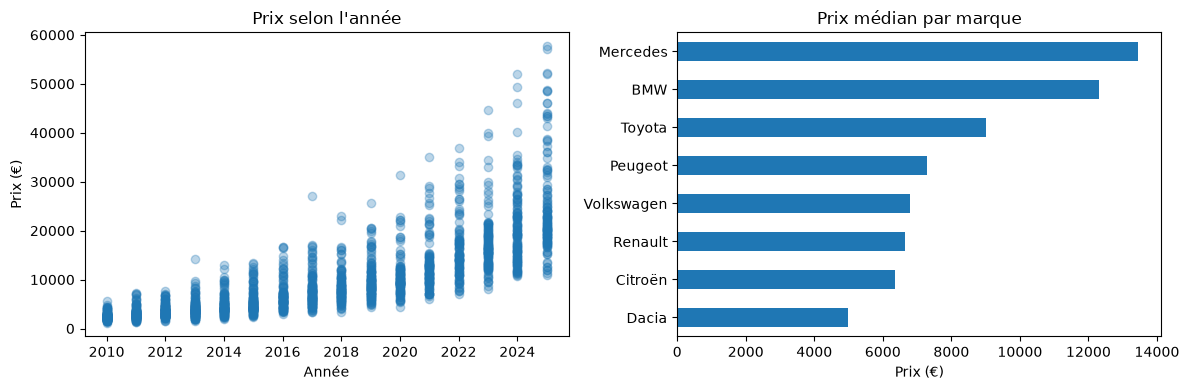

In [6]:
fig, (gauche, droite) = plt.subplots(1, 2, figsize=(12, 4))

gauche.scatter(propres["annee"], propres["prix_eur"], alpha=0.3)
gauche.set(title="Prix selon l'année", xlabel="Année", ylabel="Prix (€)")

propres.groupby("marque")["prix_eur"].median().sort_values().plot.barh(ax=droite)
droite.set(title="Prix médian par marque", xlabel="Prix (€)", ylabel="")

plt.tight_layout()
plt.show()

À gauche, le prix baisse nettement avec l'âge, surtout les premières années, puis de plus en plus lentement. À droite, la marque compte beaucoup : le prix médian d'une Mercedes (13 450 €) est presque trois fois celui d'une Dacia (4 975 €). Il faut donc donner la marque au modèle.

## 7. Séparer (étape 5)

On met 20 % des annonces **au coffre** : le modèle ne les verra jamais pendant sa construction.
Elles serviront une seule fois, à la fin, à mesurer la version retenue.

In [7]:
X = propres.drop(columns=["id_annonce", "prix_eur"])
y = propres["prix_eur"]
X_appr, X_test, y_appr, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_appr), "annonces pour apprendre,", len(X_test), "au coffre")

1584 annonces pour apprendre, 397 au coffre


## 8. La référence (étape 6)

Sans aucun modèle, le site pourrait suggérer à tout le monde le même prix : le prix médian.
Son erreur est le **seuil à battre**.

In [8]:
prix_median = y_appr.median()
erreur_reference = mean_absolute_error(y_test, [prix_median] * len(y_test))
print("Suggérer toujours", round(prix_median), "€ : erreur moyenne de", round(erreur_reference), "€")

Suggérer toujours 7300 € : erreur moyenne de 5412 €


## 9. Le pipeline (étape 7)

Le pipeline enchaîne la préparation et le modèle dans un seul objet :

| Pour | Préparation |
|---|---|
| les nombres | remplir les valeurs manquantes par la médiane, puis normaliser |
| les catégories | une colonne 0/1 par valeur (encodage) |
| tout | la régression linéaire |

Tout ce que la préparation apprend (médianes, échelles, liste des marques) est appris sur les
données d'apprentissage, puis figé.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

# Les nombres : remplir les cases vides par la médiane, puis normaliser
preparation_nombres = Pipeline([
    ("manquantes", SimpleImputer(strategy="median")),
    ("normalisation", StandardScaler()),
])
# Les catégories : une colonne 0/1 par valeur
preparation_categories = OneHotEncoder(handle_unknown="ignore")

## 10. Les versions (étape 8)

On part simple et on ajoute **une chose à la fois**. Chaque version est mesurée par
**validation croisée** sur les données d'apprentissage : 5 découpages, 5 erreurs. Leur moyenne
est l'erreur de la version ; leur variation dit ce que le hasard du découpage peut faire bouger.
Le coffre reste fermé.

In [10]:
pipeline_v1 = Pipeline([
    ("preparation", ColumnTransformer([
        ("nombres", preparation_nombres, ["annee"]),
    ])),
    ("modele", LinearRegression()),
])
cv_v1 = cross_validate(pipeline_v1, X_appr, y_appr, cv=5, scoring="neg_mean_absolute_error")
erreurs_v1 = -cv_v1["test_score"]   # scikit-learn donne les erreurs avec un signe moins
print("V1 (année) :", round(erreurs_v1.mean()), "€ ±", round(erreurs_v1.std()), "€")

V1 (année) : 3416 € ± 83 €


In [11]:
pipeline_v2 = Pipeline([
    ("preparation", ColumnTransformer([
        ("nombres", preparation_nombres, ["annee", "kilometrage"]),
    ])),
    ("modele", LinearRegression()),
])
cv_v2 = cross_validate(pipeline_v2, X_appr, y_appr, cv=5, scoring="neg_mean_absolute_error")
erreurs_v2 = -cv_v2["test_score"]   # scikit-learn donne les erreurs avec un signe moins
print("V2 (+ kilométrage) :", round(erreurs_v2.mean()), "€ ±", round(erreurs_v2.std()), "€")

V2 (+ kilométrage) : 3367 € ± 90 €


In [12]:
pipeline_v3 = Pipeline([
    ("preparation", ColumnTransformer([
        ("nombres", preparation_nombres, ["annee", "kilometrage", "puissance_ch"]),
        ("categories", preparation_categories, ["carburant", "boite"]),
    ])),
    ("modele", LinearRegression()),
])
cv_v3 = cross_validate(pipeline_v3, X_appr, y_appr, cv=5, scoring="neg_mean_absolute_error")
erreurs_v3 = -cv_v3["test_score"]   # scikit-learn donne les erreurs avec un signe moins
print("V3 (+ puissance, carburant, boîte) :", round(erreurs_v3.mean()), "€ ±", round(erreurs_v3.std()), "€")

V3 (+ puissance, carburant, boîte) : 2709 € ± 94 €


In [13]:
pipeline_v4 = Pipeline([
    ("preparation", ColumnTransformer([
        ("nombres", preparation_nombres, ["annee", "kilometrage", "puissance_ch"]),
        ("categories", preparation_categories, ["carburant", "boite", "marque"]),
    ])),
    ("modele", LinearRegression()),
])
cv_v4 = cross_validate(pipeline_v4, X_appr, y_appr, cv=5, scoring="neg_mean_absolute_error")
erreurs_v4 = -cv_v4["test_score"]   # scikit-learn donne les erreurs avec un signe moins
print("V4 (+ marque) :", round(erreurs_v4.mean()), "€ ±", round(erreurs_v4.std()), "€")

V4 (+ marque) : 2478 € ± 73 €


- V1 → V2 : le kilométrage fait gagner environ 50 €, moins que la variation (environ 90 €), donc ce gain n'est pas significatif. L'âge et le kilométrage disent presque la même chose, puisqu'une voiture ancienne a en général beaucoup roulé.
- V2 → V3 : la puissance, le carburant et la boîte font gagner environ 660 €, c'est un vrai progrès.
- V3 → V4 : la marque fait gagner environ 230 €, plus de deux fois la variation, donc c'est aussi un vrai progrès.

On garde donc la V4.

## 11. Mesurer la version retenue (fin de l'étape 8)

On ouvre le coffre, **une seule fois**, pour mesurer la version retenue sur des annonces
qu'elle n'a jamais vues.

In [14]:
modele = pipeline_v4
modele.fit(X_appr, y_appr)
erreur = mean_absolute_error(y_test, modele.predict(X_test))
print("V4        : erreur moyenne de", round(erreur), "€ sur le test")
print("Référence : erreur moyenne de", round(erreur_reference), "€")

V4        : erreur moyenne de 2439 € sur le test
Référence : erreur moyenne de 5412 €


## 12. Interpréter (étape 9)

Un modèle se lit. On prend une voiture, on change **une seule chose**, et on regarde comment
le prix suggéré bouge.

In [15]:
voiture = pd.DataFrame([{"annee": 2018, "kilometrage": 90_000, "puissance_ch": 110,
                         "carburant": "Essence", "boite": "Manuelle", "marque": "Peugeot"}])
base = modele.predict(voiture)[0]
print("Peugeot essence de 2018, 90 000 km :", round(base), "€")

plus_vieille = voiture.copy()
plus_vieille["annee"] = 2017
print("  un an de plus :", round(modele.predict(plus_vieille)[0] - base), "€ d'écart")

plus_roulee = voiture.copy()
plus_roulee["kilometrage"] = 110_000
print("  20 000 km de plus :", round(modele.predict(plus_roulee)[0] - base), "€ d'écart")

automatique = voiture.copy()
automatique["boite"] = "Automatique"
print("  boîte automatique :", round(modele.predict(automatique)[0] - base), "€ d'écart")

Peugeot essence de 2018, 90 000 km : 8644 €
  un an de plus : -1151 € d'écart
  20 000 km de plus : -297 € d'écart
  boîte automatique : 891 € d'écart


In [16]:
erreurs = X_test.copy()
erreurs["prix"] = y_test
erreurs["suggere"] = modele.predict(X_test).round(-1)
erreurs["ecart"] = (erreurs["suggere"] - erreurs["prix"]).abs()
erreurs.sort_values("ecart", ascending=False).head(5)

,marque,annee,kilometrage,carburant,boite,puissance_ch,prix,suggere,ecart
539,BMW,2025,8000,Essence,Automatique,210.0,48700,28990.0,19710.0
1378,Mercedes,2025,10000,Hybride,Automatique,NaN,43400,25400.0,18000.0
1690,BMW,2025,8400,Diesel,Automatique,160.0,41300,27320.0,13980.0
816,Volkswagen,2025,9300,Hybride,Automatique,150.0,34900,23030.0,11870.0
1138,Mercedes,2025,20400,Essence,Automatique,NaN,36150,24320.0,11830.0


À kilométrage égal, une année de plus fait baisser le prix suggéré d'environ 1 150 €. 20 000 km de plus le font baisser d'environ 300 €, et une boîte automatique l'augmente d'environ 900 €. Les plus grosses erreurs concernent des voitures chères et récentes, des BMW et des Mercedes de 2025 sous-estimées de 12 000 à 20 000 €. C'est logique : une droite suppose qu'une voiture perd la même somme chaque année, alors qu'en réalité elle en perd surtout au début.

## 13. Livrer (étape 10)

Le site ne refait pas tout ce notebook à chaque annonce : on enregistre le pipeline dans un
fichier, et le site le recharge. Le pipeline prépare tout seul une annonce brute, même avec une
valeur manquante.

In [17]:
joblib.dump(modele, "modele_prix_voiture.joblib")
site = joblib.load("modele_prix_voiture.joblib")

annonce = pd.DataFrame([{"annee": 2020, "kilometrage": 60_000, "puissance_ch": np.nan,
                         "carburant": "Hybride", "boite": "Automatique", "marque": "Toyota"}])
prix = site.predict(annonce)[0]
print("Prix suggéré : environ", round(prix), "€")

Prix suggéré : environ 14856 €


## 14. Conclusion pour Roulez Malin

Le prix suggéré se trompe en moyenne d'environ 2 440 €, contre 5 410 € si on proposait à tout le monde le prix médian. C'est plus de deux fois mieux. Le site peut donc l'afficher, mais comme une fourchette indicative et jamais comme un prix garanti, car l'erreur reste importante pour des voitures qui valent en médiane 7 300 €. Le modèle ne connaît ni l'état de la voiture, ni ses options, ni son entretien, et il se trompe davantage sur les voitures chères et récentes. Pour l'améliorer, il faudrait ajouter l'état et les options dans les annonces, et essayer un modèle qui suit mieux la décote.